# Projeto Integrador Avançado: VulcanTech Smart Metals S.A.
## Etapa 3: Visão Computacional Industrial (CVOps) — Inspeção de Solda e Análise Termográfica HAZ

Este notebook implementa e valida os pipelines de visão computacional em tempo real:
- **Inspeção Geométrica de Cordão de Solda (OpenCV)**:
  - Filtro de nitidez via kernel convolucional 3x3;
  - Conversão em tons de cinza e suavização Gaussiana;
  - Algoritmo **Canny Edge Detection**;
  - Mensuração de microporosidade interna (poros/bolhas de gás aprisionadas) e integridade dimensional/descontinuidade do cordão.
- **Análise Termográfica da Zona Afetada pelo Calor (HAZ - Heat Affected Zone)**:
  - Conversão para o espaço de cores **HSV**;
  - Limiarização bimodal (*thresholding*) para isolamento de comprimentos de onda de alta energia térmica;
  - Operações morfológicas elípticas de abertura e fechamento;
  - Detecção de focos críticos de sobreaquecimento térmico com risco de trincas na matriz e fragilização metalúrgica.

In [1]:
import os
from pathlib import Path
import sys

# Ajusta o diretório de trabalho para a raiz do repositório
caminho_raiz = Path.cwd().parent
if str(caminho_raiz) not in sys.path:
    sys.path.append(str(caminho_raiz))
os.chdir(caminho_raiz)

# Importações de visão computacional e visualização
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.vision.generate_samples import gerar_amostras_soldagem
from src.vision.weld_inspector import WeldGeometricInspector
from src.vision.thermal_haz_inspector import ThermalHAZInspector

# Configuração visual dos plots
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
print(f'Ambiente inicializado na raiz: {os.getcwd()}')


Ambiente inicializado na raiz: C:\Users\andre_matteussi\Documents\GitHub\vulcantech-edge-ai


## 1. Geração e Inicialização das Amostras de Bancada
Geração das amostras sintéticas reproduzindo cenários de juntas soldadas com arco robótico MIG/MAG e perfis térmicos infravermelhos.

Amostras de visao geradas com sucesso em:
- C:\Users\andre_matteussi\Documents\GitHub\vulcantech-edge-ai\data\raw\vision\geometric
- C:\Users\andre_matteussi\Documents\GitHub\vulcantech-edge-ai\data\raw\vision\thermal


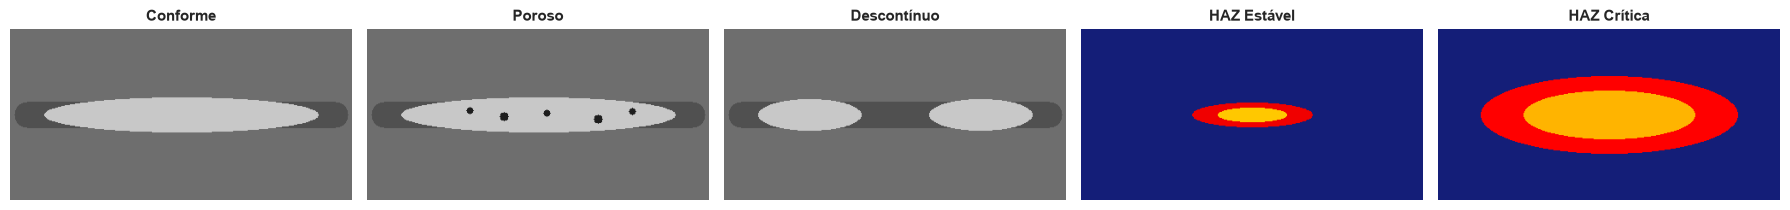

In [2]:
gerar_amostras_soldagem()

dir_geom = 'data/raw/vision/geometric'
dir_therm = 'data/raw/vision/thermal'

arquivos = {
    'Conforme': f'{dir_geom}/amostra_cordao_conforme.png',
    'Poroso': f'{dir_geom}/amostra_cordao_poroso.png',
    'Descontínuo': f'{dir_geom}/amostra_cordao_descontinuo.png',
    'HAZ Estável': f'{dir_therm}/termografia_haz_estavel.png',
    'HAZ Crítica': f'{dir_therm}/termografia_haz_critica.png',
}

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (rotulo, caminho) in zip(axes, arquivos.items()):
    img = cv2.imread(caminho)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb)
    ax.set_title(rotulo, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()


## 2. Inspeção Geométrica do Cordão de Solda (Filtro de Nitidez, Canny e Contornos)
Aplicação do pipeline `WeldGeometricInspector` para rastrear defeitos de porosidade (falhas no gás de purga) e descontinuidade física do cordão de solda.

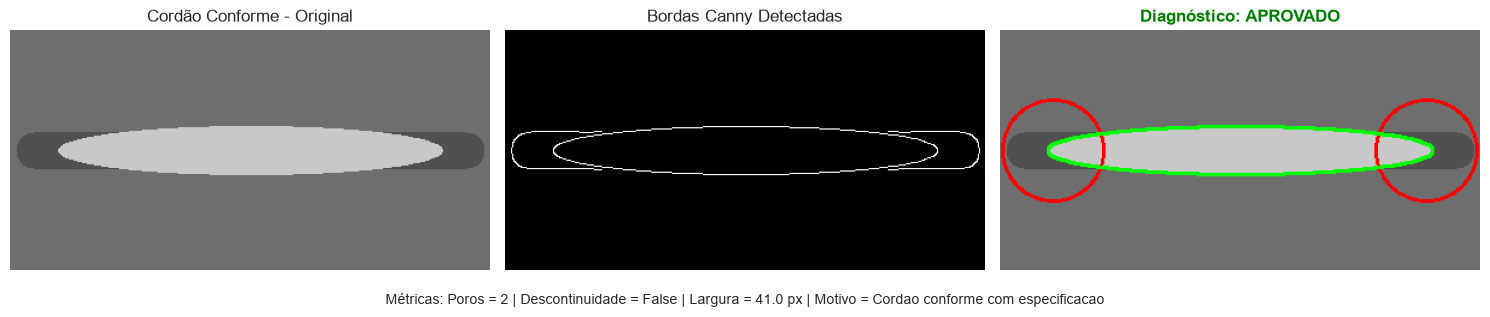

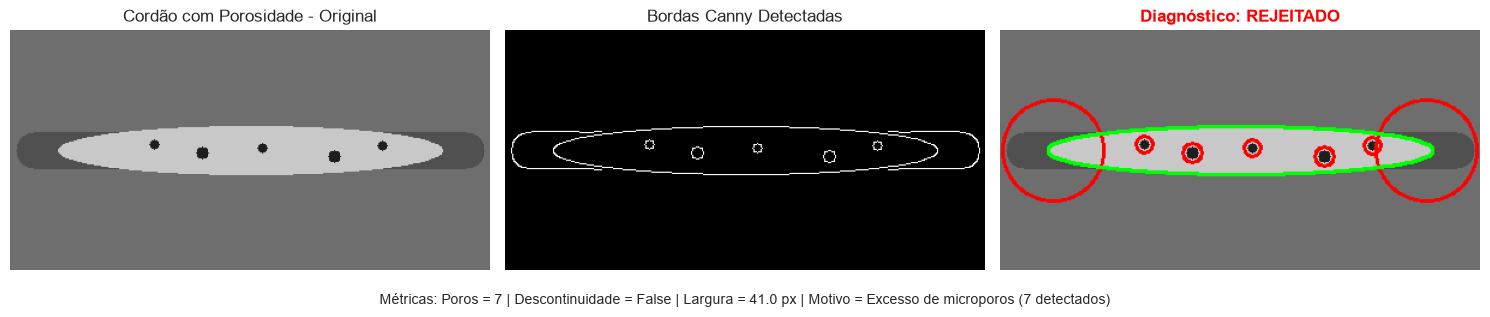

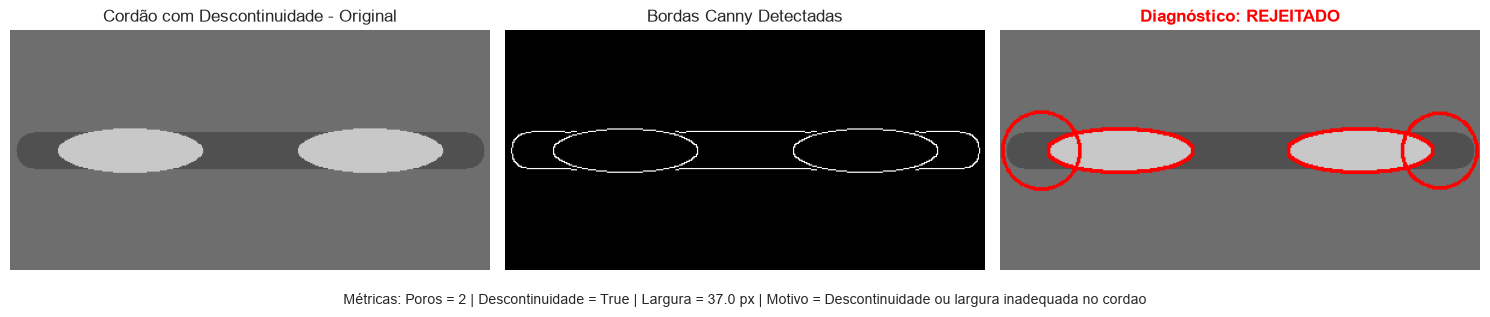

In [3]:
inspector_geometrico = WeldGeometricInspector()

amostras_geometricas = [
    ('Cordão Conforme', f'{dir_geom}/amostra_cordao_conforme.png'),
    ('Cordão com Porosidade', f'{dir_geom}/amostra_cordao_poroso.png'),
    ('Cordão com Descontinuidade', f'{dir_geom}/amostra_cordao_descontinuo.png'),
]

for titulo, caminho in amostras_geometricas:
    img = cv2.imread(caminho)
    resultado = inspector_geometrico.inspecionar_cordao(img)

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))

    # Imagem Original
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f'{titulo} - Original')
    axes[0].axis('off')

    # Máscara Canny
    axes[1].imshow(resultado['mascara_bordas'], cmap='gray')
    axes[1].set_title('Bordas Canny Detectadas')
    axes[1].axis('off')

    # Imagem Anotada
    axes[2].imshow(cv2.cvtColor(resultado['imagem_anotada'], cv2.COLOR_BGR2RGB))
    status_cor = 'green' if resultado['aprovado'] else 'red'
    status_txt = 'APROVADO' if resultado['aprovado'] else 'REJEITADO'
    axes[2].set_title(f'Diagnóstico: {status_txt}', color=status_cor, fontweight='bold')
    axes[2].axis('off')

    plt.suptitle(
        f"Métricas: Poros = {resultado['total_poros']} | "
        f"Descontinuidade = {resultado['descontinuidade']} | "
        f"Largura = {resultado['largura_media_px']} px | "
        f"Motivo = {resultado['motivo']}",
        fontsize=10,
        y=0.05
    )
    plt.tight_layout()
    plt.show()


## 3. Análise Termográfica da Zona Afetada pelo Calor (HAZ no Espaço HSV)
Processamento infravermelho no espaço de cores HSV para mapear a dilatação térmica da HAZ e isolar hotspots severos.

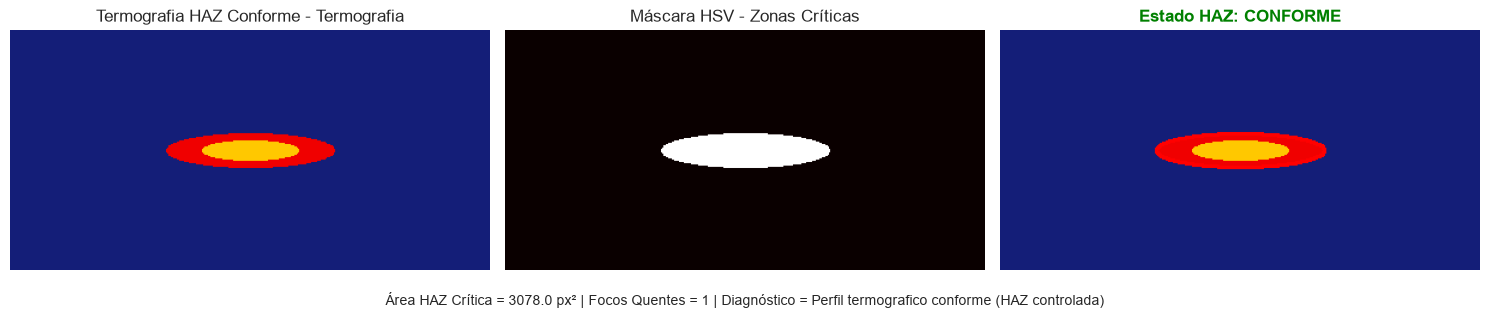

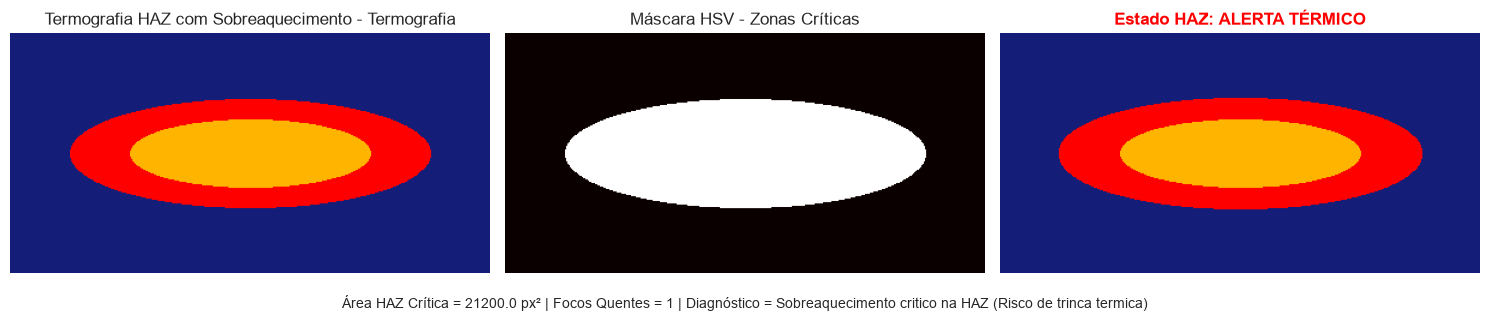

In [4]:
inspector_termico = ThermalHAZInspector()

amostras_termicas = [
    ('Termografia HAZ Conforme', f'{dir_therm}/termografia_haz_estavel.png'),
    ('Termografia HAZ com Sobreaquecimento', f'{dir_therm}/termografia_haz_critica.png'),
]

for titulo, caminho in amostras_termicas:
    img = cv2.imread(caminho)
    resultado = inspector_termico.inspecionar_termografia_haz(img)

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))

    # Termografia Original
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f'{titulo} - Termografia')
    axes[0].axis('off')

    # Máscara Binária HSV
    axes[1].imshow(resultado['mascara_termica'], cmap='hot')
    axes[1].set_title('Máscara HSV - Zonas Críticas')
    axes[1].axis('off')

    # Anotação com Contornos
    axes[2].imshow(cv2.cvtColor(resultado['imagem_anotada'], cv2.COLOR_BGR2RGB))
    status_cor = 'green' if resultado['aprovado'] else 'red'
    status_txt = 'CONFORME' if resultado['aprovado'] else 'ALERTA TÉRMICO'
    axes[2].set_title(f'Estado HAZ: {status_txt}', color=status_cor, fontweight='bold')
    axes[2].axis('off')

    plt.suptitle(
        f"Área HAZ Crítica = {resultado['area_critica_px']} px² | "
        f"Focos Quentes = {resultado['focos_detectados']} | "
        f"Diagnóstico = {resultado['diagnostico_termico']}",
        fontsize=10,
        y=0.05
    )
    plt.tight_layout()
    plt.show()


## 4. Tabela de Conformidade e Relatório de Inspeção Óptica
Compilação estruturada de todas as avaliações geométricas e termográficas para integração com o CLP da célula.

In [5]:
relatorio_inspecoes = []

# Avaliações Geométricas
for rotulo, caminho in amostras_geometricas:
    img = cv2.imread(caminho)
    res = inspector_geometrico.inspecionar_cordao(img)
    relatorio_inspecoes.append({
        'Subsistema': 'Óptico (Geometria)',
        'Caso de Teste': rotulo,
        'Aprovado': 'SIM' if res['aprovado'] else 'NÃO',
        'Métrica Primária': f"{res['total_poros']} microporos",
        'Métrica Secundária': f"Largura: {res['largura_media_px']} px",
        'Diagnóstico Emitido': res['motivo']
    })

# Avaliações Térmicas
for rotulo, caminho in amostras_termicas:
    img = cv2.imread(caminho)
    res = inspector_termico.inspecionar_termografia_haz(img)
    relatorio_inspecoes.append({
        'Subsistema': 'Termográfico (HAZ)',
        'Caso de Teste': rotulo,
        'Aprovado': 'SIM' if res['aprovado'] else 'NÃO',
        'Métrica Primária': f"{res['area_critica_px']} px²",
        'Métrica Secundária': f"{res['focos_detectados']} focos de calor",
        'Diagnóstico Emitido': res['diagnostico_termico']
    })

df_qualidade = pd.DataFrame(relatorio_inspecoes)
display(df_qualidade)


,Subsistema,Caso de Teste,Aprovado,Métrica Primária,Métrica Secundária,Diagnóstico Emitido
0,Óptico (Geometria),Cordão Conforme,SIM,2 microporos,Largura: 41.0 px,Cordao conforme com especificacao
1,Óptico (Geometria),Cordão com Porosidade,NÃO,7 microporos,Largura: 41.0 px,Excesso de microporos (7 detectados)
2,Óptico (Geometria),Cordão com Descontinuidade,NÃO,2 microporos,Largura: 37.0 px,Descontinuidade ou largura inadequada no cordao
3,Termográfico (HAZ),Termografia HAZ Conforme,SIM,3078.0 px²,1 focos de calor,Perfil termografico conforme (HAZ controlada)
4,Termográfico (HAZ),Termografia HAZ com Sobreaquecimento,NÃO,21200.0 px²,1 focos de calor,Sobreaquecimento critico na HAZ (Risco de trin...
